# DL4CV PA01-Q3: Two-Layer Net



### To-do

1. Fill in Your ID and Name.
2. (Programming) In `two_layer_net.py`, implement **affine_forward()** function.
3. (Programming) In `two_layer_net.py`, implement **affine_backward()** function.
4. (Programming) In `two_layer_net.py`, implement **relu_forward()** function.
5. (Programming) In `two_layer_net.py`, implement **relu_backward()** function.
6. (Programming) In `two_layer_net.py`, implement **`__init__()`** function in `class TwoLayerNet`.
7. (Programming) In `two_layer_net.py`, implement **loss()** function in `class TwoLayerNet`.
8. (Programming) In `dlcv/optim.py`, implement **sgd_momentum()** function.
9. (Programming) In `dlcv/optim.py`, implement **rmsprop()** function.
10. (Programming) In `dlcv/optim.py`, implement **adam()** function.
11. (Save Outputs) Successfully Run all the **code cells** in `Q3_two_layer_net.ipynb`, $\color{red}{\text{MUST}}$ save the outputs.
12. Submit $\color{red}{\mathtt{StudentID\_StudentName.zip}}$ file to Plato before deadline.


---

## Two-Layer Net Programming Assignment

In this Programming Assignment you will:
    
- implement forward and backward pass of affine transformation layer.
- implement forward and backward pass of ReLU layer.
- implement two layer net model.
- implement SGD, SGD-momentum, RMSprop, Adam optimization methods.

---

## Setup Code

### Google Colab Setup (Skip If Local Machine)

Unzip the `PA01.zip` file, upload entire `DeepLearning4ComputerVision` folder into Google drivers `My Drive` folder.

Next we need to run a few commands to set up our environment on Google Colab. If you are running this notebook on a local machine you can skip this section.

Run the following cell to mount your Google Drive. Follow the link, sign in to your Google account (the same account you used to store this notebook!) and copy the authorization code into the text box that appears below.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'DeepLearning4ComputerVision/PA01'

import os
import sys

#sys.path.append('/content/drive/My Drive/{}'.format(GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)) # if not working, try this line instead
os.chdir('/content/drive/My Drive/{}'.format(GOOGLE_DRIVE_PATH_AFTER_MYDRIVE))

# Print current working directory
print("Current Working Directory:", os.getcwd())

# List files to make sure your data is visible
print("Available Files:", os.listdir())

If the output shows
> Mounted at /content/drive
> 
> Current Working Directory: /content/drive/My Drive/DeepLearning4ComputerVision/PA01
> 
> Available Files: ['datasets', 'dlcv', 'knn.py', 'softmax.py', ...]

Then, the Google Colab is working correctly.

### python env and ipynb setup (Local Machine Run from here) (Google Colab run this)

In [3]:
import sys
import importlib
sys.modules["imp"] = importlib
# Notebook will reload external python modules;
%load_ext autoreload
%autoreload 2

import numpy as np

import matplotlib.pyplot as plt
# This is a bit of magic to make matplotlib figures appear inline in the notebook
# rather than in a new window.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

## CIFAR-10 Data Loading and Preprocessing

In [4]:
from dlcv.data_utils import get_CIFAR10_data
# Load the (preprocessed) CIFAR10 data.
cifar10_dir = 'datasets/cifar-10-batches-py'

data = get_CIFAR10_data(cifar10_dir)
for k, v in list(data.items()):
  print(('%s: ' % k, v.shape))

('X_train: ', (49000, 3, 32, 32))
('y_train: ', (49000,))
('X_val: ', (1000, 3, 32, 32))
('y_val: ', (1000,))
('X_test: ', (1000, 3, 32, 32))
('y_test: ', (1000,))


## Affine transformation layer and ReLU layer

### What's the difference? **Affine** vs **Linear**

#### Mathematically:

A true linear transformation is: $y = Wx$. No bias term.

An affine transformation is: $y = Wx + b$. With bias term.

#### Deep learning

In deep learning, a **linear layer** usually performs an **affine transformation**.
Layers such as PyTorch's `nn.Linear` compute: $y = Wx+b$ and called **linear layers**.



### Implement affine transformation forward pass

In `two_layer_net.py`, implement **affine_forward()** function.

In [5]:
# Test the affine_forward function
from two_layer_net import affine_forward
from dlcv.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array

num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])

# Compare your output with ours. The error should be around e-9 or less.
print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769849468192957e-10


### Implement affine transformation backward pass

In `two_layer_net.py`, implement **affine_backward()** function.

In [6]:
from two_layer_net import affine_backward

# Test the affine_backward function
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

# The error should be around e-10 or less
print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  5.399100368651805e-11
dw error:  9.904211865398145e-11
db error:  2.4122867568119087e-11


### Implement ReLU forward pass

In `two_layer_net.py`, implement **relu_forward()** function.

In [7]:
# Test the relu_forward function
from two_layer_net import relu_forward
x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Compare your output with ours. The error should be on the order of e-8
print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


### Implement ReLU backward pass

In `two_layer_net.py`, implement **relu_backward()** function.

In [8]:
from two_layer_net import relu_backward
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# The error should be on the order of e-12
print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  3.2756349136310288e-12


## Two-Layer Net

Given 

$$
X, Y, W_1, b_1, W_2, b_2
$$

Consider a two-layer neural network:

$$
XW_1+b_1=H_1
$$

$$
\operatorname{ReLU}(H_1)=H_2
$$

$$
H_2W_2+b_2=Z
$$

$$
\operatorname{Softmax}(Z)=S
$$

$$
\operatorname{CrossEntropy}(S,Y)=L.
$$

The complete forward flow is



$$
\boxed{
X
\rightarrow
\underbrace{
XW_1+b_1
\rightarrow
\operatorname{ReLU}(H_1)
}_{\text{First Layer}}
\rightarrow
\underbrace{
H_2W_2+b_2
\rightarrow
\operatorname{Softmax}(Z)
}_{\text{Second Layer}}
\rightarrow
L.
}
$$

### Implement Two-Layer Net's weight initialization and forward pass and backward pass

#### Weight Initialization
In `two_layer_net.py`, implement **`__init__()`** function in `class TwoLayerNet`.

#### forward pass and backward pass
In `two_layer_net.py`, implement **loss()** function in `class TwoLayerNet`.

In [14]:
from two_layer_net import TwoLayerNet
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

# Errors should be around e-7 or less
for reg in [0.0, 0.7]:
  print('Running numeric gradient check with reg = ', reg)
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg =  0.0
W1 relative error: 1.83e-08
W2 relative error: 3.20e-10
b1 relative error: 9.83e-09
b2 relative error: 4.33e-10
Running numeric gradient check with reg =  0.7
W1 relative error: 2.53e-07
W2 relative error: 2.85e-08
b1 relative error: 1.56e-08
b2 relative error: 9.09e-10


In [15]:
from dlcv.solver import Solver

input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
model = TwoLayerNet(input_size, hidden_size, num_classes, reg=1e-3)

solver = Solver(model, data, optim_config={'learning_rate': 3e-4})
solver.train()


(Iteration 1 / 4900) loss: 2.300166
(Epoch 0 / 10) train acc: 0.147000; val_acc: 0.147000
(Iteration 11 / 4900) loss: 2.292650
(Iteration 21 / 4900) loss: 2.283214
(Iteration 31 / 4900) loss: 2.256580
(Iteration 41 / 4900) loss: 2.268718
(Iteration 51 / 4900) loss: 2.227587
(Iteration 61 / 4900) loss: 2.158507
(Iteration 71 / 4900) loss: 2.065477
(Iteration 81 / 4900) loss: 2.121682
(Iteration 91 / 4900) loss: 2.060053
(Iteration 101 / 4900) loss: 1.976183
(Iteration 111 / 4900) loss: 2.015545
(Iteration 121 / 4900) loss: 2.019148
(Iteration 131 / 4900) loss: 1.942471
(Iteration 141 / 4900) loss: 1.980707
(Iteration 151 / 4900) loss: 1.937387
(Iteration 161 / 4900) loss: 1.863394
(Iteration 171 / 4900) loss: 2.057035
(Iteration 181 / 4900) loss: 1.930777
(Iteration 191 / 4900) loss: 1.951109
(Iteration 201 / 4900) loss: 1.885435
(Iteration 211 / 4900) loss: 1.822247
(Iteration 221 / 4900) loss: 1.929629
(Iteration 231 / 4900) loss: 1.791188
(Iteration 241 / 4900) loss: 1.781905
(Iterat

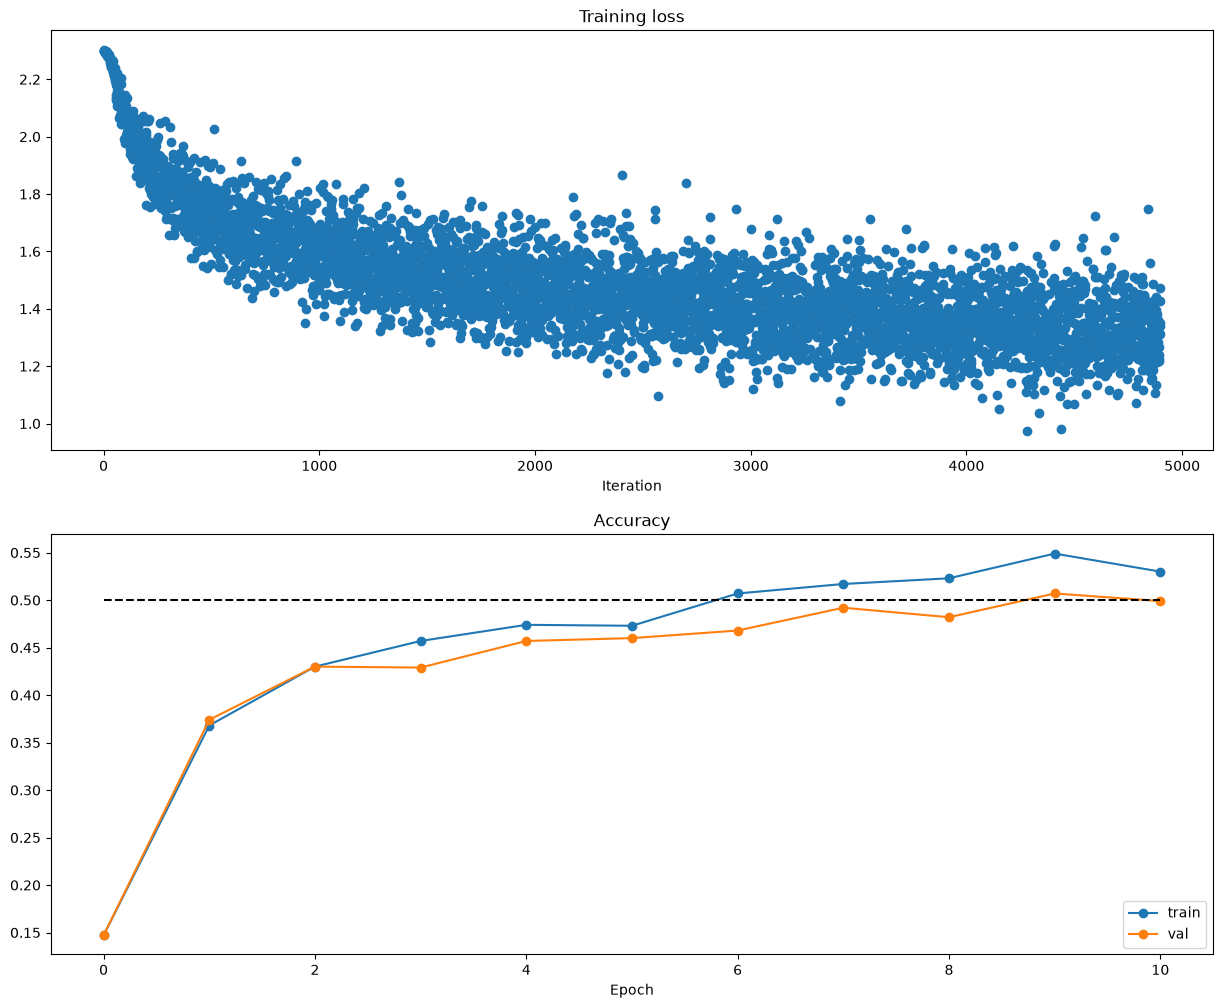

In [16]:
# Run this cell to visualize training loss and train / val accuracy

plt.subplot(2, 1, 1)
plt.title('Training loss')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Iteration')

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(solver.train_acc_history, '-o', label='train')
plt.plot(solver.val_acc_history, '-o', label='val')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

## Optimization Methods

### Implement SGD Momentum

In `dlcv/optim.py`, implement **sgd_momentum()** function.

In [17]:
from dlcv.optim import sgd_momentum

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {"learning_rate": 1e-3, "velocity": v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Should see relative errors around e-8 or less
print("next_w error: ", rel_error(next_w, expected_next_w))
print("velocity error: ", rel_error(expected_velocity, config["velocity"]))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


### Implement RMSprop

In `dlcv/optim.py`, implement **rmsprop()** function.

In [18]:
# Test RMSProp implementation
from dlcv.optim import rmsprop

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('cache error: ', rel_error(expected_cache, config['cache']))

next_w error:  9.524687511038133e-08
cache error:  2.6477955807156126e-09


### Implement Adam

In `dlcv/optim.py`, implement **adam()** function.

In [19]:
# Test Adam implementation
from dlcv.optim import adam

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

# You should see relative errors around e-7 or less
print('next_w error: ', rel_error(expected_next_w, next_w))
print('v error: ', rel_error(expected_v, config['v']))
print('m error: ', rel_error(expected_m, config['m']))

next_w error:  0.20720703668629928
v error:  4.208314038113071e-09
m error:  4.214963193114416e-09


Running with  sgd
(Iteration 1 / 5) loss: 2.308025
(Epoch 1 / 5) train acc: 0.260000; val_acc: 0.095000
(Epoch 2 / 5) train acc: 0.420000; val_acc: 0.116000
(Epoch 3 / 5) train acc: 0.440000; val_acc: 0.125000
(Epoch 4 / 5) train acc: 0.440000; val_acc: 0.124000
(Epoch 5 / 5) train acc: 0.400000; val_acc: 0.123000

Running with  sgd_momentum
(Iteration 1 / 5) loss: 2.304265
(Epoch 1 / 5) train acc: 0.260000; val_acc: 0.133000
(Epoch 2 / 5) train acc: 0.460000; val_acc: 0.153000
(Epoch 3 / 5) train acc: 0.500000; val_acc: 0.148000
(Epoch 4 / 5) train acc: 0.440000; val_acc: 0.147000
(Epoch 5 / 5) train acc: 0.420000; val_acc: 0.149000

Running with  adam
(Iteration 1 / 5) loss: 2.302561
(Epoch 1 / 5) train acc: 0.240000; val_acc: 0.128000
(Epoch 2 / 5) train acc: 0.360000; val_acc: 0.115000
(Epoch 3 / 5) train acc: 0.320000; val_acc: 0.115000
(Epoch 4 / 5) train acc: 0.360000; val_acc: 0.124000
(Epoch 5 / 5) train acc: 0.440000; val_acc: 0.136000

Running with  rmsprop
(Iteration 1 / 5)

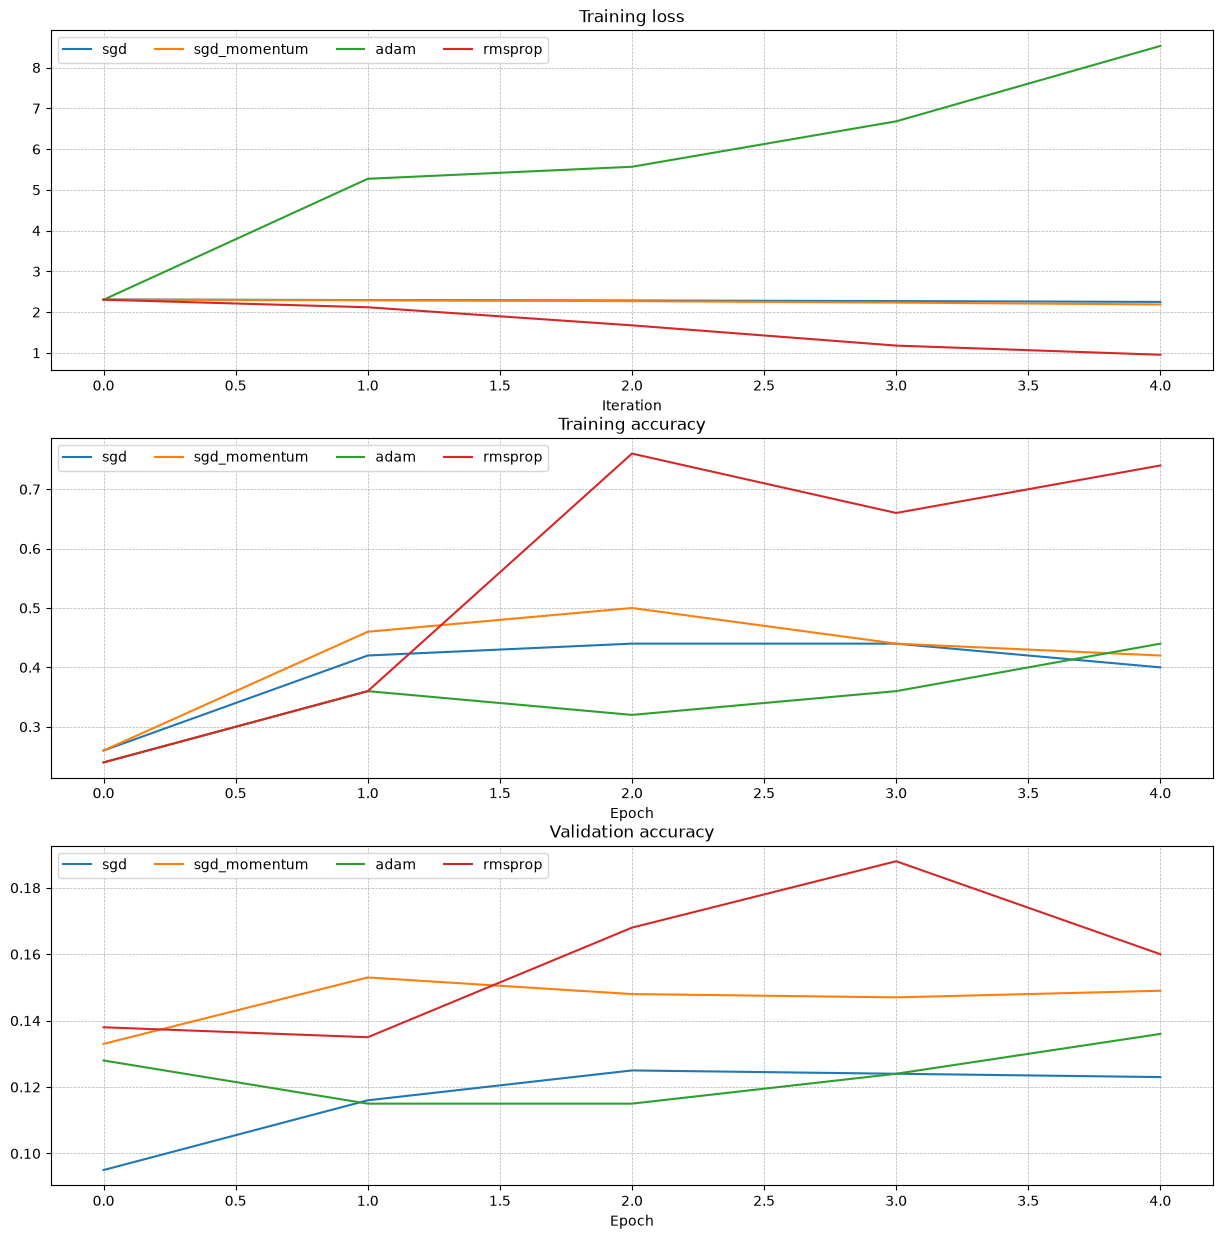

In [20]:
num_train = 50
small_data = {
  "X_train": data["X_train"][:num_train],
  "y_train": data["y_train"][:num_train],
  "X_val": data["X_val"],
  "y_val": data["y_val"],
}
solvers = {}


learning_rates = {'sgd': 1e-3, 'sgd_momentum': 1e-3, 'rmsprop': 1e-4, 'adam': 1e-3}
for update_rule in ['sgd', 'sgd_momentum', 'adam', 'rmsprop']:
    print('Running with ', update_rule)
    model = TwoLayerNet(input_size, hidden_size, num_classes, reg=1e-3)
    
    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': learning_rates[update_rule]},
        verbose=True
    )
    solvers[update_rule] = solver
    solver.train()
    print()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Training loss')
axes[0].set_xlabel('Iteration')
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[2].set_title('Validation accuracy')
axes[2].set_xlabel('Epoch')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"{update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"{update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"{update_rule}")

for ax in axes:
    ax.legend(loc='best', ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()